# Playbook interactif — segmentation de vêtements

Ce notebook accompagne `PLAYBOOK.md` et guide l'utilisation du projet depuis la racine du dépôt.

> **Attention :** l'exécution complète appelle un service de segmentation externe ou local. Les appels en ligne peuvent entraîner des coûts. Aucune cellule n'est exécutée automatiquement ; lancez uniquement celles dont vous avez besoin.

## 1. Prérequis et configuration

Depuis la racine du dépôt, créez un environnement virtuel et installez les dépendances :

```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
pip install -r requirements.txt
```

Créez `.env` à partir de `.env.example`. Configurez `token` pour le mode Hugging Face en ligne ; choisissez `api_local=true` pour le service local. `only_test=true` saute la segmentation et lance seulement l'évaluation IoU. `max_images` vaut 3 par défaut.

Ne collez pas de token dans le notebook et ne l'affichez pas dans une cellule.

In [1]:
import os
from pathlib import Path

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'main.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Impossible de trouver main.py depuis le dossier courant.')

os.chdir(PROJECT_ROOT)
print(f'Racine du projet : {PROJECT_ROOT}')

Racine du projet : d:\Dev\VSC\RNCP_DEV_IA\p4\fashion_trend_intelligence_test


## 2. Vérifier la configuration et les dossiers

Cette cellule affiche uniquement si un token est présent, jamais sa valeur. Elle n'ajoute ni ne crée aucun dossier.

In [2]:
from dotenv import load_dotenv

load_dotenv(PROJECT_ROOT / '.env')
print(f"Token configuré : {'oui' if os.getenv('token') else 'non'}")
print(f"Mode API : {'local' if os.getenv('api_local', 'false').strip().lower() == 'true' else 'Hugging Face'}")
print(f"Mode IoU seul : {os.getenv('only_test', 'false').strip().lower() == 'true'}")
print(f"Nombre maximum d'images : {os.getenv('max_images', '3')}")

required_dirs = [
    Path('assets/IMG'),
    Path('assets/Mask'),
    Path('assets/Reference'),
    Path('resultats_segmentation'),
]
for directory in required_dirs:
    print(f"{'OK' if directory.is_dir() else 'MANQUANT'} : {directory}")

input_images = sorted(
    path for path in Path('assets/IMG').glob('*')
    if path.is_file() and path.suffix.lower() in {'.jpg', '.png'}
)
print(f'Images .jpg/.png trouvées : {len(input_images)}')
for path in input_images:
    print(f' - {path}')

Token configuré : oui
Mode API : local
Mode IoU seul : False
Nombre maximum d'images : 3
OK : assets\IMG
OK : assets\Mask
OK : assets\Reference
OK : resultats_segmentation
Images .jpg/.png trouvées : 3
 - assets\IMG\image_0.png
 - assets\IMG\image_1.png
 - assets\IMG\image_2.png


## 3. Lancer le traitement complet

Vérifiez d'abord le mode affiché par la cellule précédente. Le mode en ligne nécessite un token Hugging Face valide ; le mode local nécessite un serveur accessible sur `http://localhost:8000/segment`. Dans `main.py`, les images retenues sont sélectionnées sans tri garanti : vérifiez la liste affichée par le script.

La sortie de `main.py` (y compris les erreurs) sera affichée en direct dans cette cellule. Exécutez-la uniquement si vous souhaitez lancer les appels de segmentation.

In [ ]:
import subprocess
import sys

run_env = os.environ.copy()
run_env['PYTHONIOENCODING'] = 'utf-8'
with subprocess.Popen(
    [sys.executable, '-u', 'main.py'],
    cwd=PROJECT_ROOT,
    env=run_env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    encoding='utf-8',
    bufsize=1,
) as process:
    if process.stdout is None:
        raise RuntimeError('Impossible de lire la sortie de main.py.')
    for line in process.stdout:
        print(line, end='', flush=True)
    return_code = process.wait()

print(f'Code de sortie de main.py : {return_code}')
if return_code != 0:
    raise RuntimeError('main.py a échoué ; consultez les messages affichés ci-dessus.')

### Résultats attendus

- Masques prédits : `assets/Mask/mask_<nom_image>`.
- Comparaisons image/masque : `resultats_segmentation/<nom_image>_comparison.png`.
- Montages colorisés avec légende : `resultats_segmentation/result_<index>.png`.
- Scores IoU par fichier et par classe dans la sortie de `main.py`.

Les identifiants de classe vont de 0 à 17 ; la classe 0 correspond au fond et est exclue de la moyenne IoU hors fond.

## 4. Évaluer les masques sans relancer la segmentation

La cellule suivante lance `main.py` dans un processus séparé avec `only_test=true` et affiche sa sortie en direct. Elle ne modifie pas l'environnement global du notebook. L'évaluation compare **tous** les fichiers de `assets/Mask` et `assets/Reference`, appariés par nom exact ; les dossiers et les paires doivent exister.

In [9]:
iou_env = os.environ.copy()
iou_env['only_test'] = 'true'
iou_env['PYTHONIOENCODING'] = 'utf-8'
with subprocess.Popen(
    [sys.executable, '-u', 'main.py'],
    cwd=PROJECT_ROOT,
    env=iou_env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    encoding='utf-8',
    bufsize=1,
) as process:
    if process.stdout is None:
        raise RuntimeError('Impossible de lire la sortie de main.py.')
    for line in process.stdout:
        print(line, end='', flush=True)
    return_code = process.wait()

print(f'Code de sortie de main.py (IoU seul) : {return_code}')
if return_code != 0:
    raise RuntimeError('L’évaluation IoU a échoué ; consultez les messages affichés ci-dessus.')

Dossier 'assets/IMG' existant.
Mode : local -> http://localhost:8000/segment
3 image(s) à traiter : ['assets/IMG\\image_0.png', 'assets/IMG\\image_1.png', 'assets/IMG\\image_2.png']
Valeur de only_test : True

Mode test uniquement activé.
Seules les évaluations IoU seront effectuées.

Évaluation IoU des masques prédits par rapport aux références...
mask_image_0.png : IoU moyenne hors fond = 86.9%
mask_image_1.png : IoU moyenne hors fond = 84.5%
mask_image_2.png : IoU moyenne hors fond = 93.6%

Bilan IoU : 3 paire(s) comparée(s).
IoU moyenne globale hors fond : 87.9%
  Classe 1 (Hat) : IoU moyenne = 98.4%
  Classe 2 (Hair) : IoU moyenne = 97.8%
  Classe 4 (Upper-clothes) : IoU moyenne = 96.8%
  Classe 5 (Skirt) : IoU moyenne = 72.6%
  Classe 6 (Pants) : IoU moyenne = 97.6%
  Classe 7 (Dress) : IoU moyenne = 76.8%
  Classe 9 (Left-shoe) : IoU moyenne = 87.7%
  Classe 10 (Right-shoe) : IoU moyenne = 78.9%
  Classe 11 (Face) : IoU moyenne = 98.0%
  Classe 12 (Left-leg) : IoU moyenne = 86.1

## 5. Afficher une comparaison

Après un traitement réussi, la cellule ci-dessous affiche `result_0.png` ainsi que la première comparaison trouvée.

resultats_segmentation\result_0.png


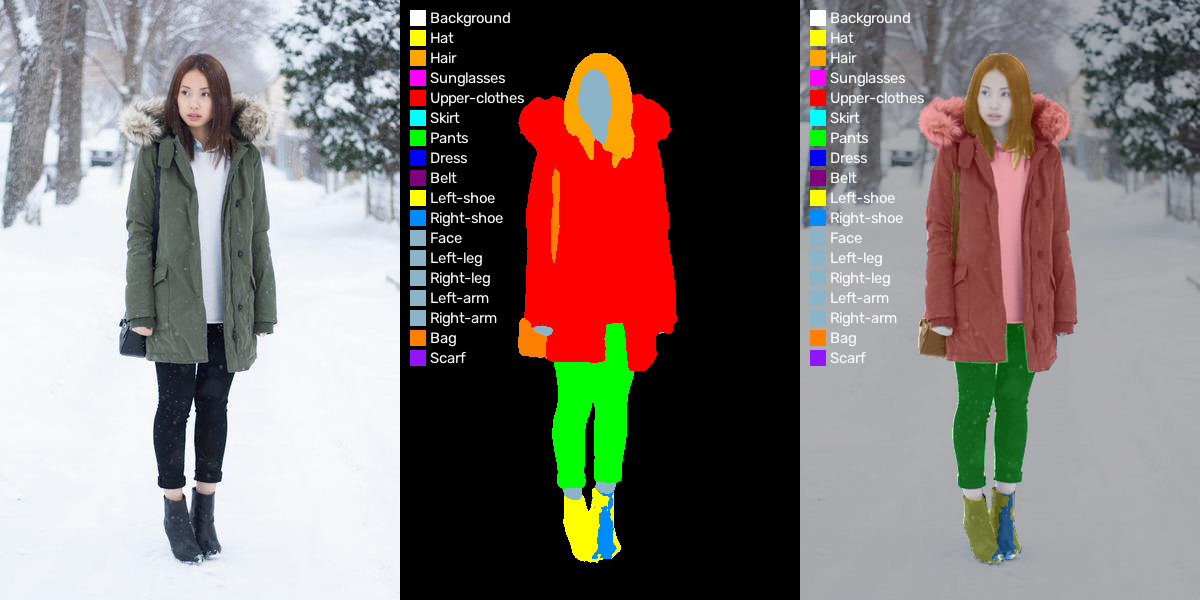

resultats_segmentation\image_0_comparison.png


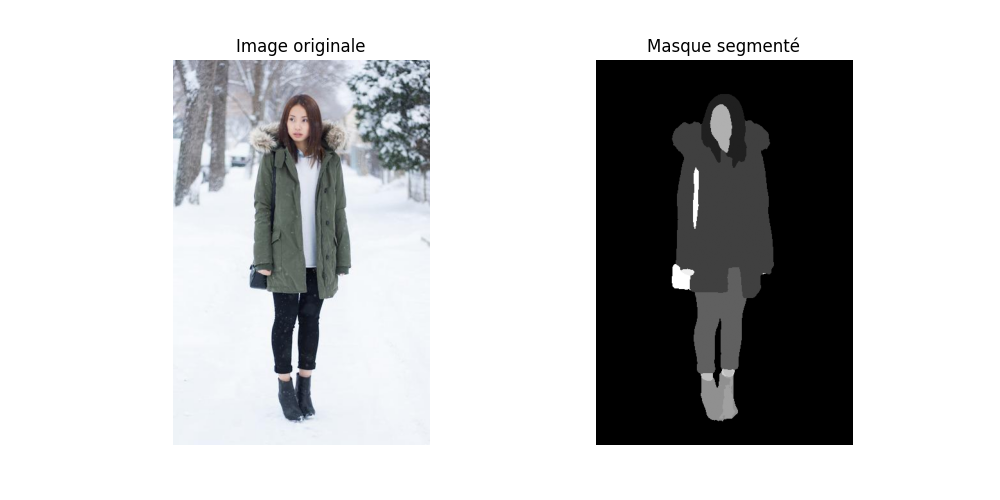

In [6]:
from IPython.display import display
from PIL import Image

result_0 = Path('resultats_segmentation/result_0.png')
if result_0.is_file():
    print(result_0)
    display(Image.open(result_0))
else:
    print(f'{result_0} est absent ; lancez le traitement complet pour le générer.')

comparisons = sorted(Path('resultats_segmentation').glob('*_comparison.png'))
if comparisons:
    print(comparisons[0])
    display(Image.open(comparisons[0]))
else:
    print('Aucune comparaison trouvée. Lancez le traitement complet et vérifiez ses messages.')

## 6. Dépannage et limites connues

- **Images absentes :** `main.py` sélectionne les fichiers `.jpg` et `.png` de `assets/IMG`. Vérifiez la liste de fichiers affichée au démarrage.
- **Erreur d'API :** vérifier le token et l'accès réseau en ligne, ou le démarrage du serveur local sur `localhost:8000/segment`.
- **Erreur IoU :** vérifier la présence des dossiers `assets/Mask` et `assets/Reference`, les noms de fichiers identiques, les dimensions et les identifiants de classe.
- `max_images` limite les images sélectionnées pour la segmentation, pas le nombre de masques évalués par l'IoU.
- Les montages utilisent les images et les masques triés séparément puis les associent par position. Des masques anciens ou des listes non alignées peuvent produire des comparaisons incorrectes.
- Pour plus de détails, consulter [`PLAYBOOK.md`](PLAYBOOK.md).